### Import libraries and set random seeds

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.5.3


### Create output folders

In [2]:
OUTPUT_DIR = Path("outputs")
PLOT_DIR = Path("visualizations")
OUTPUT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

print("Outputs will be saved to:", OUTPUT_DIR.resolve())
print("Visualizations will be saved to:", PLOT_DIR.resolve())

Outputs will be saved to: F:\Internship_Projects\Intership_0\Week_5\outputs
Visualizations will be saved to: F:\Internship_Projects\Intership_0\Week_5\visualizations


### Load the MNIST dataset

In [3]:
(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train_raw.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test.shape)
print("Pixel range before normalization:", x_train_raw.min(), "to", x_train_raw.max())

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Pixel range before normalization: 0 to 255


### Explore sample images and class distribution

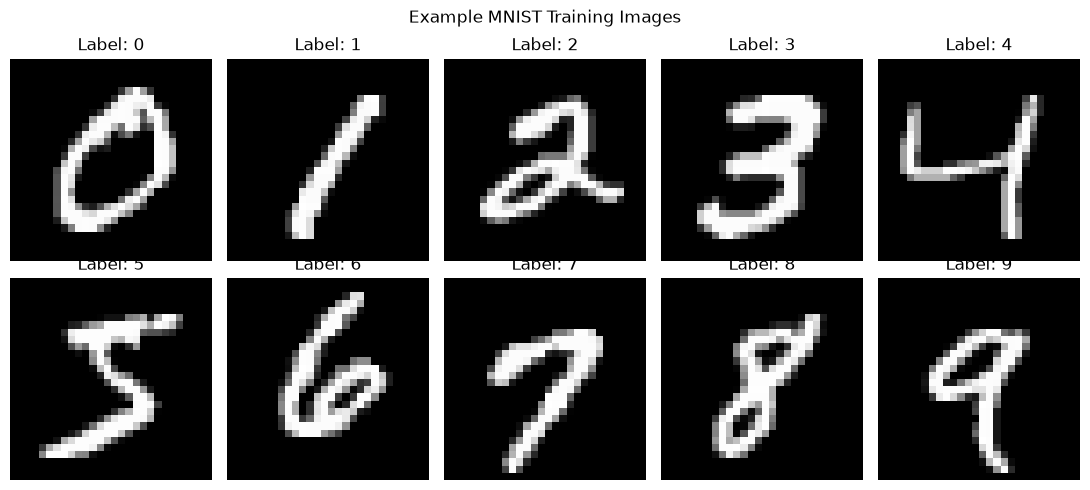

,digit,count,percentage
0,0,5923,9.87
1,1,6742,11.24
2,2,5958,9.93
3,3,6131,10.22
4,4,5842,9.74
5,5,5421,9.04
6,6,5918,9.86
7,7,6265,10.44
8,8,5851,9.75
9,9,5949,9.92


In [4]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for digit, ax in enumerate(axes.flat):
    idx = np.where(y_train == digit)[0][0]
    ax.imshow(x_train_raw[idx], cmap="gray")
    ax.set_title(f"Label: {y_train[idx]}")
    ax.axis("off")
plt.suptitle("Example MNIST Training Images")
plt.tight_layout()
plt.show()

class_counts = pd.Series(y_train).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "digit": class_counts.index,
    "count": class_counts.values,
    "percentage": (class_counts.values / len(y_train) * 100).round(2)
})
display(class_distribution)

### Prepare and normalize the image data
Pixel values are converted to `float32` and divided by 255 so they fall in the range [0, 1]. A channel dimension is added because `Conv2D` expects images with height, width, and channels.

In [5]:
x_train = np.expand_dims(x_train_raw.astype("float32") / 255.0, axis=-1)
x_test = np.expand_dims(x_test_raw.astype("float32") / 255.0, axis=-1)

print("Prepared training shape:", x_train.shape)
print("Prepared test shape:", x_test.shape)
print("Normalized pixel range:", float(x_train.min()), "to", float(x_train.max()))

# Numerical examples
print("128 / 255 =", round(128 / 255, 4))
print("255 / 255 =", round(255 / 255, 4))

Prepared training shape: (60000, 28, 28, 1)
Prepared test shape: (10000, 28, 28, 1)
Normalized pixel range: 0.0 to 1.0
128 / 255 = 0.502
255 / 255 = 1.0


### Define the CNN architecture
The CNN uses two convolution/pooling blocks to learn visual patterns, a dense layer to combine learned features, dropout to help reduce overfitting, and a 10-unit softmax output for digit classes 0–9.

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### Architecture diagram

```text
Input image (28 × 28 × 1)
          |
Conv2D: 32 filters, 3×3, ReLU
          |
MaxPooling2D: 2×2  → 14 × 14 × 32
          |
Conv2D: 64 filters, 3×3, ReLU
          |
MaxPooling2D: 2×2  → 7 × 7 × 64
          |
Flatten → 3,136 features
          |
Dense: 128 units, ReLU
          |
Dropout: 30%
          |
Dense: 10 units, Softmax
          |
Predicted digit: 0–9
```

### Calculate trainable parameters
This calculation provides a numerical check on the model architecture. Confirm the exact count in `model.summary()`.

In [7]:
parameter_calculation = pd.DataFrame([
    ["Conv2D 1", (3 * 3 * 1 + 1) * 32],
    ["Conv2D 2", (3 * 3 * 32 + 1) * 64],
    ["Dense 128", (7 * 7 * 64 * 128) + 128],
    ["Dense 10", (128 * 10) + 10],
], columns=["Layer", "Trainable parameters"])

display(parameter_calculation)
print("Calculated total trainable parameters:", int(parameter_calculation["Trainable parameters"].sum()))
print("Flatten and Dropout layers have no trainable parameters.")

,Layer,Trainable parameters
0,Conv2D 1,320
1,Conv2D 2,18496
2,Dense 128,401536
3,Dense 10,1290


Calculated total trainable parameters: 421642
Flatten and Dropout layers have no trainable parameters.


### Configure callbacks and train the model
The model trains for up to 15 epochs with batch size 128. Ten percent of the original training pool is used for validation. Early stopping monitors validation loss and restores the best weights. A checkpoint saves the best model.

In [8]:
EPOCHS = 15
BATCH_SIZE = 128

checkpoint_path = OUTPUT_DIR / "best_mnist_cnn.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    x_train,
    y_train,
    validation_split=0.10,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9249 - loss: 0.2479
Epoch 1: val_loss improved from None to 0.05879, saving model to outputs\best_mnist_cnn.keras

Epoch 1: finished saving model to outputs\best_mnist_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.9249 - loss: 0.2479 - val_accuracy: 0.9830 - val_loss: 0.0588
Epoch 2/15
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9798 - loss: 0.0670
Epoch 2: val_loss improved from 0.05879 to 0.04149, saving model to outputs\best_mnist_cnn.keras

Epoch 2: finished saving model to outputs\best_mnist_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.9798 - loss: 0.0668 - val_accuracy: 0.9878 - val_loss: 0.0415
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9847 - loss: 0.0471
Epoch 3: val_loss improved from 0.04149 to 0.03369, saving model to outputs\best_mnist_cnn.keras

Epoch 3: finished saving model to outputs\best_mnist_cnn.keras
422/422 ━━━━━━━━━━━━━

### Plot training and validation curves
Compare training and validation loss/accuracy. A growing gap—especially training loss decreasing while validation loss increases—can be a sign of overfitting. Base conclusions on the curves from your run.

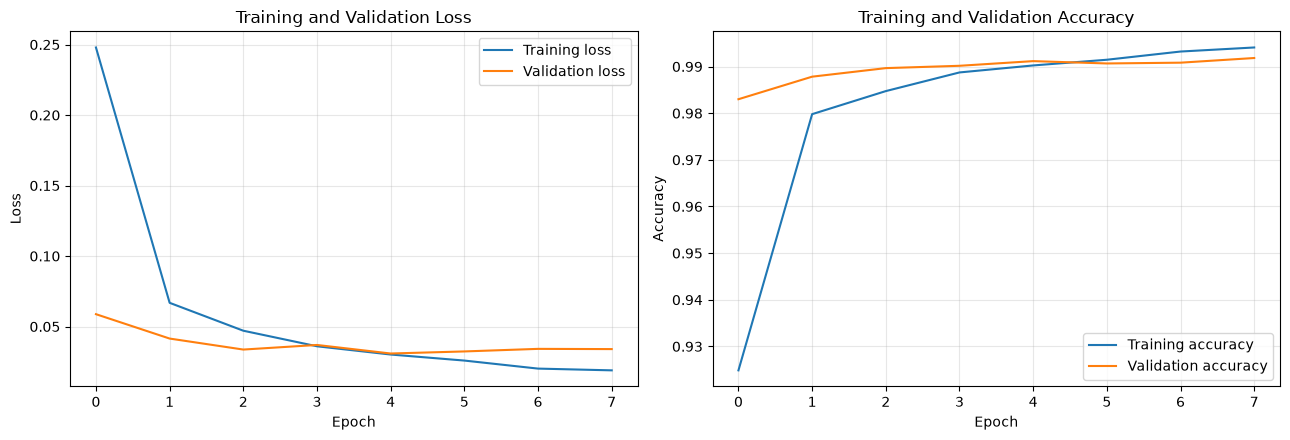

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "training_history.png", dpi=200, bbox_inches="tight")
plt.show()

### Evaluate on the held-out test set
The test set is used only after training. Macro-averaged metrics calculate each digit class's metric separately and then average the ten values equally.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_precision": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
    "epochs_completed": int(len(history.history["loss"])),
    "batch_size": BATCH_SIZE,
    "random_seed": SEED
}

metrics_df = pd.DataFrame([metrics])
display(metrics_df.round(4))

metrics_df.to_csv(OUTPUT_DIR / "evaluation_metrics.csv", index=False)
with open(OUTPUT_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved metrics to", OUTPUT_DIR / "evaluation_metrics.csv")

,test_loss,test_accuracy,macro_precision,macro_recall,macro_f1,epochs_completed,batch_size,random_seed
0,0.0253,0.9909,0.9908,0.9908,0.9908,8,128,42


Saved metrics to outputs\evaluation_metrics.csv


### Classification report by digit

In [11]:
report_text = classification_report(
    y_test, y_pred, labels=list(range(10)), digits=4, zero_division=0
)
print(report_text)

(OUTPUT_DIR / "classification_report.txt").write_text(report_text, encoding="utf-8")

              precision    recall  f1-score   support

           0     0.9939    0.9959    0.9949       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9922    0.9884    0.9903      1032
           3     0.9960    0.9911    0.9935      1010
           4     0.9879    0.9949    0.9914       982
           5     0.9823    0.9944    0.9883       892
           6     0.9958    0.9833    0.9895       958
           7     0.9874    0.9893    0.9883      1028
           8     0.9928    0.9877    0.9902       974
           9     0.9881    0.9851    0.9866      1009

    accuracy                         0.9909     10000
   macro avg     0.9908    0.9908    0.9908     10000
weighted avg     0.9909    0.9909    0.9909     10000



758

### Confusion matrix
Rows represent true labels and columns represent predicted labels. Off-diagonal values show errors. Check which digit classes are confused most often, and discuss only patterns visible in your matrix.

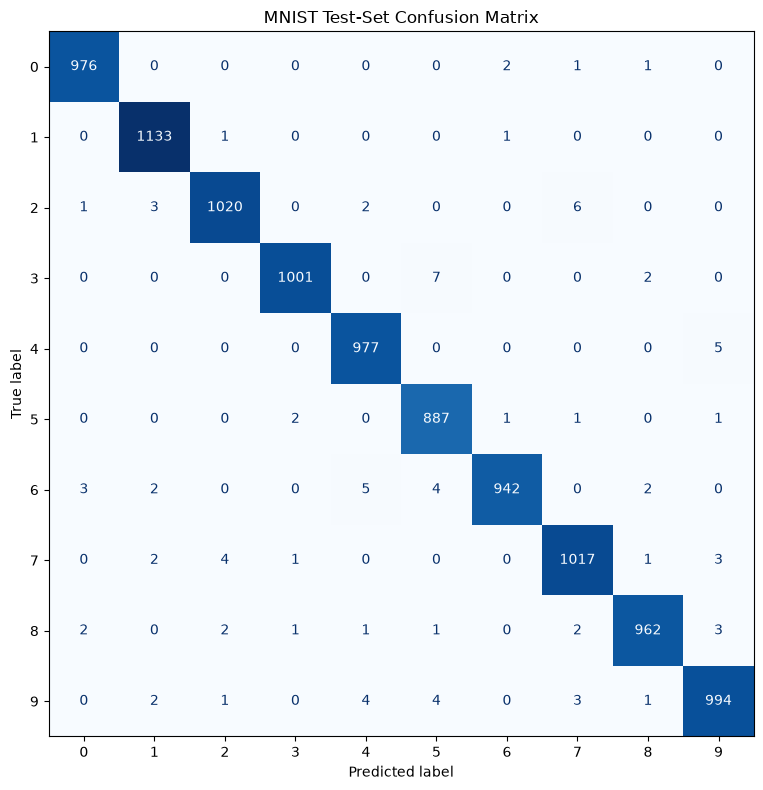

Total incorrect predictions: 91
Test error rate (%): 0.91


In [12]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("MNIST Test-Set Confusion Matrix")
plt.tight_layout()
plt.savefig(PLOT_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print("Total incorrect predictions:", int((y_pred != y_test).sum()))
print("Test error rate (%):", round((y_pred != y_test).mean() * 100, 3))

### Inspect misclassified examples

Number of misclassified test images: 91


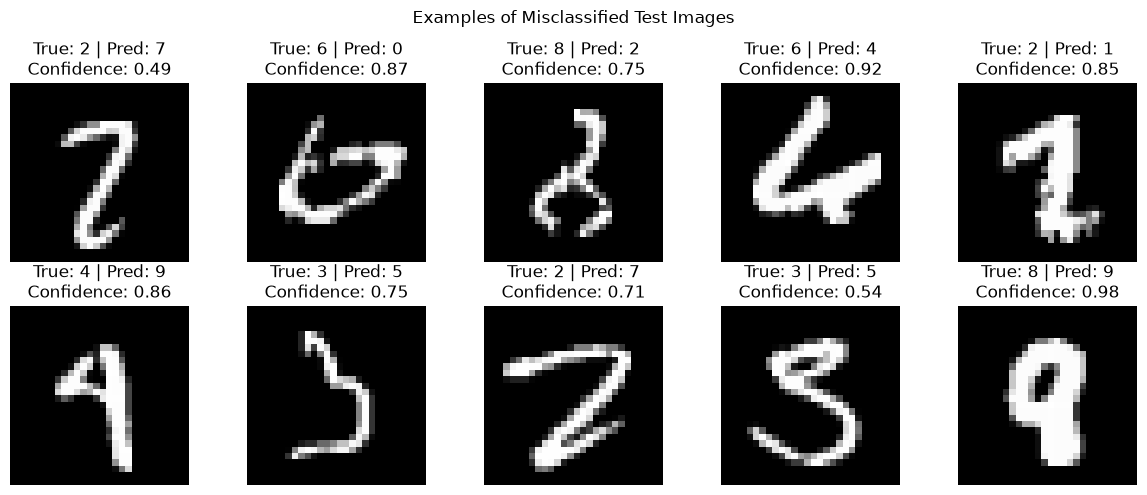

In [13]:
wrong_indices = np.where(y_pred != y_test)[0]
print("Number of misclassified test images:", len(wrong_indices))

if len(wrong_indices) > 0:
    sample_indices = wrong_indices[:10]
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax, idx in zip(axes.flat, sample_indices):
        ax.imshow(x_test[idx].squeeze(), cmap="gray")
        ax.set_title(
            f"True: {y_test[idx]} | Pred: {y_pred[idx]}\n"
            f"Confidence: {probabilities[idx].max():.2f}"
        )
        ax.axis("off")
    plt.suptitle("Examples of Misclassified Test Images")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "misclassified_examples.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No errors found in this test run; inspect additional samples if needed.")

### Save predictions and trained model

In [14]:
predictions_df = pd.DataFrame({
    "actual_digit": y_test,
    "predicted_digit": y_pred,
    "confidence": probabilities.max(axis=1),
    "correct": y_test == y_pred
})
predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

model.save(OUTPUT_DIR / "mnist_cnn_final.keras")

print("Saved predictions:", OUTPUT_DIR / "test_predictions.csv")
print("Saved final model:", OUTPUT_DIR / "mnist_cnn_final.keras")
display(predictions_df.head(10))

Saved predictions: outputs\test_predictions.csv
Saved final model: outputs\mnist_cnn_final.keras


,actual_digit,predicted_digit,confidence,correct
0,7,7,0.999998,True
1,2,2,0.999993,True
2,1,1,0.999990,True
3,0,0,0.999929,True
4,4,4,0.999964,True
5,1,1,0.999997,True
6,4,4,0.999230,True
7,9,9,0.998810,True
8,5,5,0.995453,True
9,9,9,0.999982,True


### Results-based analysis prompts
Use the actual output above to complete these points in your report:

1. State the measured test accuracy and macro F1-score.
2. Report the total number of incorrect predictions and calculate the error rate.
3. Identify one or two digit pairs with high confusion-matrix counts, if present.
4. Compare training and validation curves. Is there evidence of a widening gap?
5. Explain one limitation of using MNIST as a proxy for real-world handwriting.
6. Suggest a change to test next, such as data augmentation or a different model configuration.

Do not claim that overfitting occurred or that one digit pair was commonly confused unless your plots support that conclusion.

### Challenges, limitations, and improvements

**Potential challenges:** dataset download or package installation, training time on limited hardware, overfitting, and confusion between visually similar digits.

**Mitigations used:** input normalization, a compact CNN, dropout, validation monitoring, early stopping, and saving the best checkpoint.

**Limitations:** MNIST images are small, centered, and grayscale. Real documents may contain noisy, rotated, low-resolution, or multi-character images. Test-set performance alone does not establish suitability for a real deployment.

**Possible improvements:** compare against a dense-network baseline, test data augmentation, tune learning rate and dropout using validation data, and evaluate on a separate real-handwriting dataset.

### Conclusion

This notebook demonstrates an end-to-end deep-learning workflow: loading and preparing data, designing a CNN, training with validation monitoring, evaluating on held-out test data, and inspecting errors. Write the final conclusion after reviewing your actual metrics and visualizations. Include the measured accuracy and macro F1-score, a specific observation from the confusion matrix, and one limitation or next step.